In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    raise RuntimeError("GPU not detected. Enable the T4 GPU in Colab.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4
GPU memory (GB): 15.64


In [2]:
%pip install -q transformers datasets accelerate \
    scikit-learn pandas matplotlib seaborn

In [3]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import random
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("\nTraining features:")
print(dataset["train"].features)

print("\nExample:")
print(dataset["train"][0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Training features:
{'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}

Example:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [4]:
label_names = dataset["train"].features["label"].names

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

train_df["category"] = train_df["label"].map(
    dict(enumerate(label_names))
)
test_df["category"] = test_df["label"].map(
    dict(enumerate(label_names))
)

print("Training samples:", len(train_df))
print("Official test samples:", len(test_df))
print("Number of categories:", len(label_names))

print("\nTraining class distribution:")
print(train_df["category"].value_counts().sort_index())

print("\nTraining class percentages:")
print(
    (train_df["category"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Training samples: 120000
Official test samples: 7600
Number of categories: 4

Training class distribution:
category
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64

Training class percentages:
category
Business    25.0
Sci/Tech    25.0
Sports      25.0
World       25.0
Name: proportion, dtype: float64


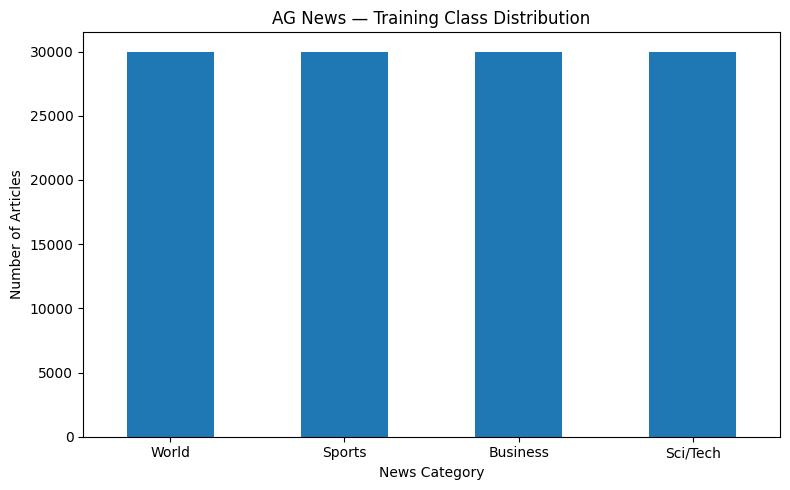

In [13]:
import matplotlib.pyplot as plt

counts = train_df["category"].value_counts().reindex(label_names)

plt.figure(figsize=(8, 5))
counts.plot(kind="bar")
plt.title("AG News — Training Class Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=300)
plt.show()

In [5]:
split = dataset["train"].train_test_split(
    test_size=0.10,
    seed=SEED,
    stratify_by_column="label"
)

train_data = split["train"]
val_data = split["test"]
test_data = dataset["test"]

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Official test:", len(test_data))

Training: 108000
Validation: 12000
Official test: 7600


In [8]:
for split_name, split_data in [
    ("Train", train_data),
    ("Validation", val_data),
    ("Test", test_data),
]:
    counts = pd.Series(split_data["label"]).value_counts().sort_index()
    print(f"\n{split_name}")
    for label_id, count in counts.items():
        print(f"{label_names[label_id]}: {count}")


Train
World: 27000
Sports: 27000
Business: 27000
Sci/Tech: 27000

Validation
World: 3000
Sports: 3000
Business: 3000
Sci/Tech: 3000

Test
World: 1900
Sports: 1900
Business: 1900
Sci/Tech: 1900


In [9]:
import json

split_summary = {
    "dataset": "fancyzhx/ag_news",
    "seed": SEED,
    "train_samples": len(train_data),
    "validation_samples": len(val_data),
    "test_samples": len(test_data),
    "labels": label_names
}

with open("dataset_information.json", "w") as f:
    json.dump(split_summary, f, indent=4)

print(json.dumps(split_summary, indent=4))

{
    "dataset": "fancyzhx/ag_news",
    "seed": 42,
    "train_samples": 108000,
    "validation_samples": 12000,
    "test_samples": 7600,
    "labels": [
        "World",
        "Sports",
        "Business",
        "Sci/Tech"
    ]
}


In [10]:
import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

X_train = list(train_data["text"])
y_train = list(train_data["label"])

X_val = list(val_data["text"])
y_val = list(val_data["label"])


def evaluate_baseline(name, model, X_train, y_train, X_val, y_val):
    start = time.time()
    model.fit(X_train, y_train)
    train_seconds = time.time() - start

    start = time.time()
    predictions = model.predict(X_val)
    inference_seconds = time.time() - start

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Training Time (seconds)": round(train_seconds, 2),
        "Validation Prediction Time (seconds)": round(inference_seconds, 2)
    }


logistic_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=100_000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=100_000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        random_state=42
    ))
])

baseline_results = []

baseline_results.append(
    evaluate_baseline(
        "TF-IDF + Logistic Regression",
        logistic_model,
        X_train, y_train, X_val, y_val
    )
)

baseline_results.append(
    evaluate_baseline(
        "TF-IDF + Linear SVM",
        svm_model,
        X_train, y_train, X_val, y_val
    )
)

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df.round(4))

baseline_df.to_csv("baseline_validation_results.csv", index=False)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training Time (seconds),Validation Prediction Time (seconds)
0,TF-IDF + Logistic Regression,0.9194,0.9193,0.9194,0.9193,32.34,0.79
1,TF-IDF + Linear SVM,0.9220,0.9219,0.9220,0.9219,21.58,0.80


In [14]:
import os
from google.colab import files

files_to_download = [
    "baseline_validation_results.csv",
    "class_distribution.png",
    "dataset_information.json"
]

for file_name in files_to_download:
    if os.path.exists(file_name):
        files.download(file_name)
    else:
        print(f"Warning: '{file_name}' not found in the current directory. Please re-run the cell that generates this file.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [16]:
import os

PROJECT_DIR = "/content/drive/MyDrive/News_Classification_Project"
MODEL_DIR = os.path.join(PROJECT_DIR, "models", "distilbert")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures")

for folder in [MODEL_DIR, RESULTS_DIR, FIGURES_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /content/drive/MyDrive/News_Classification_Project


In [17]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 192

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_train = train_data.map(
    tokenize_batch, batched=True
)
tokenized_val = val_data.map(
    tokenize_batch, batched=True
)
tokenized_test = test_data.map(
    tokenize_batch, batched=True
)

print(tokenized_train[0].keys())
print("Tokenisation complete.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/108000 [00:00<?, ? examples/s]

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

dict_keys(['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'])
Tokenisation complete.


In [18]:
from transformers import AutoModelForSequenceClassification

id2label = {i: name for i, name in enumerate(label_names)}
label2id = {name: i for i, name in enumerate(label_names)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

print("Device:", device)
print(
    "Total parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Total parameters: 66,956,548
Trainable parameters: 66,956,548


In [19]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = logits.argmax(axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

training_args = TrainingArguments(
    output_dir=MODEL_DIR,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=100,
    lr_scheduler_type="linear",
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    greater_is_better=True,
    fp16=True,
    logging_strategy="steps",
    logging_steps=100,
    report_to="none",
    seed=42,
    data_seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer configured successfully.")

Trainer configured successfully.


In [20]:
import time

start_time = time.time()

train_output = trainer.train()

training_seconds = time.time() - start_time

print(f"Training time: {training_seconds / 60:.2f} minutes")
print("Training metrics:", train_output.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.197036,0.186436,0.940083,0.940353,0.940083,0.940108
2,0.102656,0.205194,0.943333,0.944320,0.943333,0.943357
3,0.119937,0.220735,0.946917,0.947279,0.946917,0.946945


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 18.44 minutes
Training metrics: {'train_runtime': 1105.5288, 'train_samples_per_second': 293.072, 'train_steps_per_second': 18.317, 'total_flos': 8063073100900608.0, 'train_loss': 0.15935691160037194, 'epoch': 3.0}


In [21]:
trainer.save_model(MODEL_DIR)
tokenizer.save_pretrained(MODEL_DIR)

print("Model saved to:", MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/drive/MyDrive/News_Classification_Project/models/distilbert


In [22]:
import json

history = trainer.state.log_history

with open(
    os.path.join(RESULTS_DIR, "training_history.json"), "w"
) as f:
    json.dump(history, f, indent=2)

print("Training history saved.")

Training history saved.


In [23]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt

with open(
    os.path.join(RESULTS_DIR, "training_history.json"), "r"
) as f:
    history = json.load(f)

history_df = pd.DataFrame(history)

display(history_df.tail(15))

,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_macro_precision,eval_macro_recall,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
191,0.107436,2.858298,1.241687e-06,2.814815,19000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
192,0.090884,0.508168,1.142432e-06,2.829630,19100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
193,0.107246,1.818594,1.043176e-06,2.844444,19200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
194,0.097414,0.017895,9.439206e-07,2.859259,19300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
195,0.110885,1.030645,8.446650e-07,2.874074,19400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
196,0.094790,11.997555,7.454094e-07,2.888889,19500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
197,0.080578,0.630503,6.461538e-07,2.903704,19600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
198,0.105135,7.579342,5.468983e-07,2.918519,19700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
199,0.101964,0.321305,4.476427e-07,2.933333,19800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
200,0.092091,1.475487,3.483871e-07,2.948148,19900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


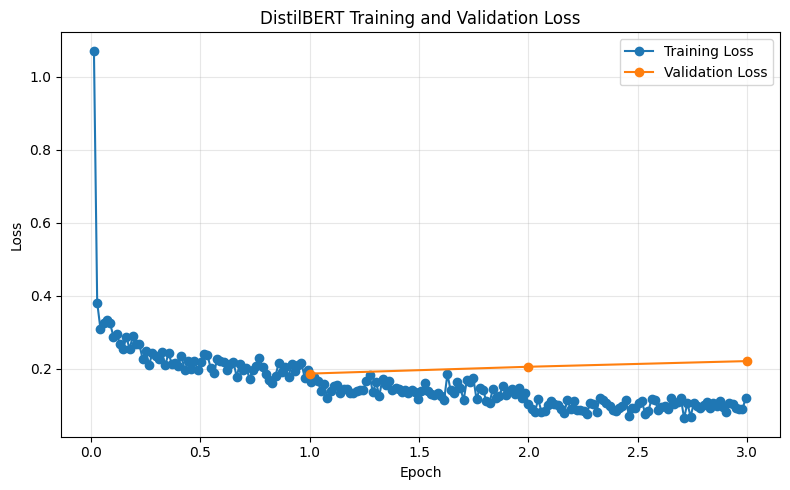

In [24]:
loss_df = history_df.dropna(
    subset=["loss", "epoch"]
)[["epoch", "loss"]].copy()

eval_df = history_df.dropna(
    subset=["eval_loss", "epoch"]
)[["epoch", "eval_loss"]].copy()

plt.figure(figsize=(8, 5))
plt.plot(loss_df["epoch"], loss_df["loss"], marker="o",
         label="Training Loss")
plt.plot(eval_df["epoch"], eval_df["eval_loss"], marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DistilBERT Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "training_validation_loss.png"),
    dpi=300
)
plt.show()

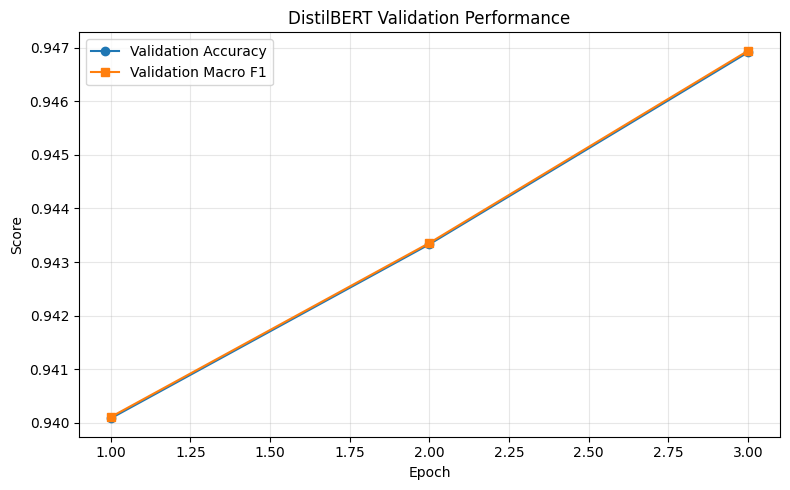

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    eval_df["epoch"],
    history_df.dropna(subset=["eval_accuracy"])["eval_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    eval_df["epoch"],
    history_df.dropna(subset=["eval_macro_f1"])["eval_macro_f1"],
    marker="s",
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("DistilBERT Validation Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "validation_performance.png"),
    dpi=300
)
plt.show()

In [26]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score
)
import numpy as np
import time

start = time.time()

test_output = trainer.predict(tokenized_test)

test_seconds = time.time() - start

test_logits = test_output.predictions
y_true = test_output.label_ids
y_pred = np.argmax(test_logits, axis=1)

# Convert logits to probabilities for multiclass ROC-AUC
exp_logits = np.exp(
    test_logits - np.max(test_logits, axis=1, keepdims=True)
)
y_prob = exp_logits / exp_logits.sum(axis=1, keepdims=True)

print("OFFICIAL TEST RESULTS")
print("=" * 50)
print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall:    {recall:.4f}")
print(f"Macro F1:        {f1:.4f}")

print(
    "Multiclass ROC-AUC:",
    round(roc_auc_score(
        y_true, y_prob, multi_class="ovr", average="macro"
    ), 4)
)

print(f"Prediction time: {test_seconds:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred, target_names=label_names, digits=4
))

OFFICIAL TEST RESULTS
Accuracy: 0.9479
Macro Precision: 0.9481
Macro Recall:    0.9479
Macro F1:        0.9480
Multiclass ROC-AUC: 0.9933
Prediction time: 12.09 seconds

Classification Report:
              precision    recall  f1-score   support

       World     0.9602    0.9526    0.9564      1900
      Sports     0.9905    0.9853    0.9879      1900
    Business     0.9241    0.9158    0.9199      1900
    Sci/Tech     0.9176    0.9379    0.9276      1900

    accuracy                         0.9479      7600
   macro avg     0.9481    0.9479    0.9480      7600
weighted avg     0.9481    0.9479    0.9480      7600



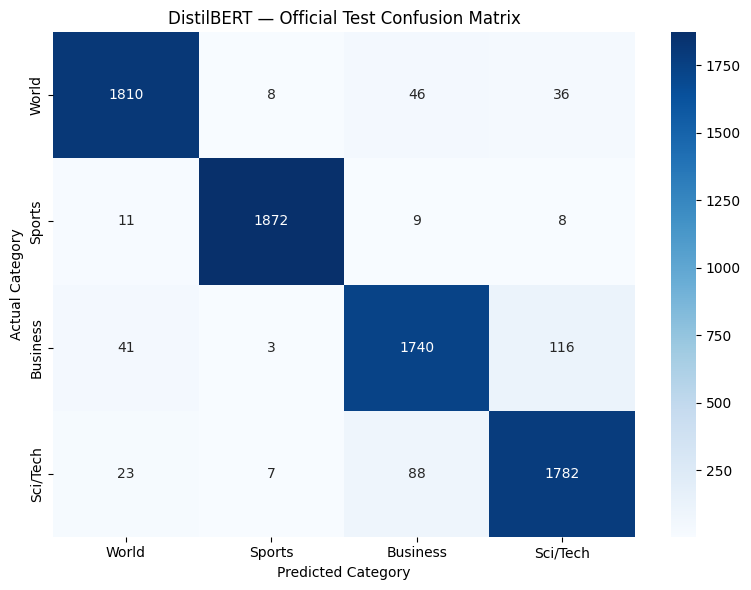

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(label_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_names,
    yticklabels=label_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("DistilBERT — Official Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "confusion_matrix.png"),
    dpi=300
)
plt.show()

In [30]:
import random
from datasets import Dataset, concatenate_datasets

AUGMENT_SEED = 42
rng = random.Random(AUGMENT_SEED)

def add_typos(text, probability=0.08):
    words = text.split()
    new_words = []

    for word in words:
        if (
            len(word) >= 5
            and rng.random() < probability
            and word.isalpha()
        ):
            i = rng.randint(1, len(word) - 2)
            chars = list(word)
            chars[i], chars[i + 1] = chars[i + 1], chars[i]
            word = "".join(chars)

        new_words.append(word)

    return " ".join(new_words)

# Generate augmented texts
augmented_texts = [
    add_typos(text)
    for text in train_data["text"]
]

# IMPORTANT: preserve the original feature types
augmented_train = Dataset.from_dict(
    {
        "text": augmented_texts,
        "label": train_data["label"]
    },
    features=train_data.features
)

combined_train = concatenate_datasets([
    train_data,
    augmented_train
]).shuffle(seed=AUGMENT_SEED)

print("Original features:", train_data.features)
print("Augmented features:", augmented_train.features)
print("Combined training examples:", len(combined_train))
print("First augmented example:", augmented_train[0])

Original features: {'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}
Augmented features: {'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}
Combined training examples: 216000
First augmented example: {'text': 'Three tied for lead at Souhtern Farm Bureau Classic John Senden carded a pair of eagles, Harrison Farzar shot a 31 on the front nine and Glen Day recorded sveen birdies to finish Thursday #39;s first round of the', 'label': 1}


In [31]:
tokenized_augmented_train = combined_train.map(
    tokenize_batch,
    batched=True
)

print("Augmented training data tokenised.")

Map:   0%|          | 0/216000 [00:00<?, ? examples/s]

Augmented training data tokenised.


In [33]:
import os
import inspect
import time
import torch
import transformers

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

# 1. Set output directory
AUG_MODEL_DIR = os.path.join(
    PROJECT_DIR, "models", "distilbert_augmented"
)
os.makedirs(AUG_MODEL_DIR, exist_ok=True)

print("Transformers version:", transformers.__version__)

# 2. Load a fresh pretrained DistilBERT model
# The new classification head is expected to be randomly initialised.
aug_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label=id2label,
    label2id=label2id
)

# 3. Detect the argument name supported by your installation
supported_args = inspect.signature(
    TrainingArguments.__init__
).parameters

evaluation_arg = (
    "eval_strategy"
    if "eval_strategy" in supported_args
    else "evaluation_strategy"
)

# 4. Configure training
aug_config = {
    "output_dir": AUG_MODEL_DIR,
    "learning_rate": 2e-5,
    "per_device_train_batch_size": 16,
    "per_device_eval_batch_size": 32,
    "num_train_epochs": 1,
    "weight_decay": 0.01,
    "warmup_steps": 500,
    "save_strategy": "epoch",
    "save_total_limit": 1,
    "fp16": torch.cuda.is_available(),
    "logging_steps": 200,
    "report_to": "none",
    "seed": 42,
    "data_seed": 42
}

aug_config[evaluation_arg] = "epoch"

aug_args = TrainingArguments(**aug_config)

# 5. Create the trainer
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

aug_trainer = Trainer(
    model=aug_model,
    args=aug_args,
    train_dataset=tokenized_augmented_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Augmented trainer configured successfully.")
print("Training examples:", len(tokenized_augmented_train))
print("Validation examples:", len(tokenized_val))
print("GPU available:", torch.cuda.is_available())

Transformers version: 5.20.1


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Augmented trainer configured successfully.
Training examples: 216000
Validation examples: 12000
GPU available: True


In [34]:
aug_start = time.time()

aug_training_output = aug_trainer.train()

aug_training_seconds = time.time() - aug_start

aug_trainer.save_model(AUG_MODEL_DIR)
tokenizer.save_pretrained(AUG_MODEL_DIR)

print(
    f"Augmented model training time: "
    f"{aug_training_seconds / 60:.2f} minutes"
)
print("Training metrics:", aug_training_output.metrics)
print("Saved model:", AUG_MODEL_DIR)

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.153015,0.189741,0.945167,0.945548,0.945167,0.945163


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Augmented model training time: 12.38 minutes
Training metrics: {'train_runtime': 742.4453, 'train_samples_per_second': 290.931, 'train_steps_per_second': 18.183, 'total_flos': 5468109793805568.0, 'train_loss': 0.20511972173055013, 'epoch': 1.0}
Saved model: /content/drive/MyDrive/News_Classification_Project/models/distilbert_augmented


In [35]:
validation_rng = random.Random(123)

def corrupt_validation_text(text):
    global rng
    old_rng = rng
    try:
        rng = validation_rng
        return add_typos(text, probability=0.08)
    finally:
        rng = old_rng

corrupted_val_texts = [
    corrupt_validation_text(text)
    for text in val_data["text"]
]

corrupted_val = Dataset.from_dict({
    "text": corrupted_val_texts,
    "label": val_data["label"]
})

tokenized_corrupted_val = corrupted_val.map(
    tokenize_batch,
    batched=True
)

print("Clean and corrupted validation sets are ready.")

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Clean and corrupted validation sets are ready.


In [36]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

def evaluate_on_dataset(evaluator, tokenized_dataset, labels, model_name, condition):
    output = evaluator.predict(tokenized_dataset)
    predictions = np.argmax(output.predictions, axis=1)

    return {
        "Model": model_name,
        "Condition": condition,
        "Accuracy": accuracy_score(labels, predictions),
        "Macro F1": f1_score(
            labels, predictions, average="macro"
        )
    }

robustness_results = [
    evaluate_on_dataset(
        trainer, tokenized_val, val_data["label"],
        "Standard DistilBERT", "Clean validation"
    ),
    evaluate_on_dataset(
        trainer, tokenized_corrupted_val, val_data["label"],
        "Standard DistilBERT", "Typo-corrupted validation"
    ),
    evaluate_on_dataset(
        aug_trainer, tokenized_val, val_data["label"],
        "Augmented DistilBERT", "Clean validation"
    ),
    evaluate_on_dataset(
        aug_trainer, tokenized_corrupted_val, val_data["label"],
        "Augmented DistilBERT", "Typo-corrupted validation"
    )
]

robustness_df = pd.DataFrame(robustness_results)
display(robustness_df.round(4))

robustness_df.to_csv(
    os.path.join(RESULTS_DIR, "robustness_ablation.csv"),
    index=False
)

,Model,Condition,Accuracy,Macro F1
0,Standard DistilBERT,Clean validation,0.9469,0.9469
1,Standard DistilBERT,Typo-corrupted validation,0.9438,0.9438
2,Augmented DistilBERT,Clean validation,0.9452,0.9452
3,Augmented DistilBERT,Typo-corrupted validation,0.9439,0.9439


In [37]:
import os
import pandas as pd

for filename in [
    "model_comparison.csv",
    "robustness_ablation.csv",
    "distilbert_test_metrics.csv",
    "per_class_specificity.csv",
]:
    path = os.path.join(RESULTS_DIR, filename)

    print(f"\n{'=' * 60}")
    print(filename)

    if os.path.exists(path):
        display(pd.read_csv(path).round(4))
    else:
        print("File not found at:", path)


model_comparison.csv
File not found at: /content/drive/MyDrive/News_Classification_Project/results/model_comparison.csv

robustness_ablation.csv


,Model,Condition,Accuracy,Macro F1
0,Standard DistilBERT,Clean validation,0.9469,0.9469
1,Standard DistilBERT,Typo-corrupted validation,0.9438,0.9438
2,Augmented DistilBERT,Clean validation,0.9452,0.9452
3,Augmented DistilBERT,Typo-corrupted validation,0.9439,0.9439



distilbert_test_metrics.csv
File not found at: /content/drive/MyDrive/News_Classification_Project/results/distilbert_test_metrics.csv

per_class_specificity.csv
File not found at: /content/drive/MyDrive/News_Classification_Project/results/per_class_specificity.csv


In [38]:
import os
import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix
)

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# ------------------------------------------
# A. Save DistilBERT official test metrics
# ------------------------------------------
p, r, f, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

pw, rw, fw, _ = precision_recall_fscore_support(
    y_true, y_pred, average="weighted", zero_division=0
)

test_metrics = {
    "Model": "DistilBERT",
    "Test Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": p,
    "Macro Recall": r,
    "Macro F1": f,
    "Weighted Precision": pw,
    "Weighted Recall": rw,
    "Weighted F1": fw,
    "Macro ROC-AUC OvR": roc_auc_score(
        y_true, y_prob, multi_class="ovr", average="macro"
    ),
    "Test Prediction Time Seconds": test_seconds,
    "Training Time Seconds": training_seconds
}

pd.DataFrame([test_metrics]).to_csv(
    os.path.join(RESULTS_DIR, "distilbert_test_metrics.csv"),
    index=False
)

# ------------------------------------------
# B. Save per-class specificity
# ------------------------------------------
cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(label_names)))
)

specificity_rows = []

for i, name in enumerate(label_names):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp

    specificity_rows.append({
        "Category": name,
        "Specificity": tn / (tn + fp) if (tn + fp) else 0
    })

pd.DataFrame(specificity_rows).to_csv(
    os.path.join(RESULTS_DIR, "per_class_specificity.csv"),
    index=False
)

# ------------------------------------------
# C. Recreate test comparison
# ------------------------------------------
comparison_rows = []

for name, baseline in [
    ("TF-IDF + Logistic Regression", logistic_model),
    ("TF-IDF + Linear SVM", svm_model)
]:
    preds = baseline.predict(list(test_data["text"]))

    bp, br, bf, _ = precision_recall_fscore_support(
        test_data["label"], preds,
        average="macro", zero_division=0
    )

    comparison_rows.append({
        "Model": name,
        "Test Accuracy": accuracy_score(test_data["label"], preds),
        "Macro Precision": bp,
        "Macro Recall": br,
        "Macro F1": bf
    })

comparison_rows.append({
    "Model": "DistilBERT",
    "Test Accuracy": test_metrics["Test Accuracy"],
    "Macro Precision": test_metrics["Macro Precision"],
    "Macro Recall": test_metrics["Macro Recall"],
    "Macro F1": test_metrics["Macro F1"]
})

comparison_df = pd.DataFrame(comparison_rows)

comparison_df.to_csv(
    os.path.join(RESULTS_DIR, "model_comparison.csv"),
    index=False
)

# ------------------------------------------
# D. Ensure robustness results are saved
# ------------------------------------------
robustness_df.to_csv(
    os.path.join(RESULTS_DIR, "robustness_ablation.csv"),
    index=False
)

# ------------------------------------------
# E. Save classification report
# ------------------------------------------
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=label_names,
    digits=4
)

with open(
    os.path.join(RESULTS_DIR, "classification_report.txt"), "w"
) as f:
    f.write(report)

# ------------------------------------------
# F. Save experiment summary
# ------------------------------------------
summary = {
    "dataset": "AG News",
    "labels": label_names,
    "train_samples": len(train_data),
    "validation_samples": len(val_data),
    "test_samples": len(test_data),
    "seed": 42,
    "standard_distilbert_test_accuracy": float(
        test_metrics["Test Accuracy"]
    ),
    "standard_distilbert_test_macro_f1": float(
        test_metrics["Macro F1"]
    ),
    "standard_training_seconds": float(training_seconds),
    "augmented_training_seconds": float(aug_training_seconds)
}

with open(
    os.path.join(RESULTS_DIR, "experiment_summary.json"), "w"
) as f:
    json.dump(summary, f, indent=2)

# ------------------------------------------
# G. Display and verify files
# ------------------------------------------
print("MODEL COMPARISON — OFFICIAL TEST SET")
display(comparison_df.round(4))

print("\nROBUSTNESS EXPERIMENT")
display(robustness_df.round(4))

print("\nDISTILBERT TEST METRICS")
display(pd.DataFrame([test_metrics]).round(4))

print("\nSAVED FILES")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print(filename)

MODEL COMPARISON — OFFICIAL TEST SET


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,TF-IDF + Logistic Regression,0.9172,0.9172,0.9172,0.9171
1,TF-IDF + Linear SVM,0.9236,0.9234,0.9236,0.9234
2,DistilBERT,0.9479,0.9481,0.9479,0.9480



ROBUSTNESS EXPERIMENT


,Model,Condition,Accuracy,Macro F1
0,Standard DistilBERT,Clean validation,0.9469,0.9469
1,Standard DistilBERT,Typo-corrupted validation,0.9438,0.9438
2,Augmented DistilBERT,Clean validation,0.9452,0.9452
3,Augmented DistilBERT,Typo-corrupted validation,0.9439,0.9439



DISTILBERT TEST METRICS


,Model,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Macro ROC-AUC OvR,Test Prediction Time Seconds,Training Time Seconds
0,DistilBERT,0.9479,0.9481,0.9479,0.948,0.9481,0.9479,0.948,0.9933,12.0913,1106.2329



SAVED FILES
classification_report.txt
distilbert_test_metrics.csv
experiment_summary.json
model_comparison.csv
per_class_specificity.csv
robustness_ablation.csv
training_history.json


In [42]:

import os
import json
import shutil
import zipfile
import importlib.metadata
from pathlib import Path

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

REGISTRATION_NUMBER = "2430010355"

PROJECT_DIR = "/content/drive/MyDrive/News_Classification_Project"
SUBMISSION_DIR = os.path.join(PROJECT_DIR, "submission")

# Check that Google Drive is mounted
if not os.path.isdir(PROJECT_DIR):
    raise FileNotFoundError(
        f"Project directory not found: {PROJECT_DIR}\n"
        "Mount Google Drive and check your project folder path."
    )

# Use existing notebook variables when available; otherwise
# use the standard project folder structure.
RESULTS_DIR = globals().get(
    "RESULTS_DIR", os.path.join(PROJECT_DIR, "results")
)
FIGURES_DIR = globals().get(
    "FIGURES_DIR", os.path.join(PROJECT_DIR, "figures")
)
MODEL_DIR = globals().get(
    "MODEL_DIR", os.path.join(PROJECT_DIR, "models", "distilbert")
)
AUG_MODEL_DIR = globals().get(
    "AUG_MODEL_DIR",
    os.path.join(PROJECT_DIR, "models", "distilbert_augmented")
)

# Output folders
FOLDERS = [
    "results",
    "figures",
    "code",
    "models",
    "notebooks",
    "reports",
    "resources",
]

# Keep an existing notebook if one is already in this folder.
os.makedirs(SUBMISSION_DIR, exist_ok=True)

for folder in FOLDERS:
    os.makedirs(os.path.join(SUBMISSION_DIR, folder), exist_ok=True)

# ------------------------------------------------------------
# 2. COPY EXISTING RESULTS AND FIGURES
# ------------------------------------------------------------

for source_dir, destination_name in [
    (RESULTS_DIR, "results"),
    (FIGURES_DIR, "figures"),
]:
    destination_dir = os.path.join(SUBMISSION_DIR, destination_name)

    if os.path.isdir(source_dir):
        for filename in os.listdir(source_dir):
            source = os.path.join(source_dir, filename)
            destination = os.path.join(destination_dir, filename)

            if os.path.isfile(source):
                shutil.copy2(source, destination)

        print(f"Copied files from: {source_dir}")
    else:
        print(f"WARNING: Source directory not found: {source_dir}")

# ------------------------------------------------------------
# 3. COPY TRAINED MODELS
# ------------------------------------------------------------

for source, destination_name in [
    (MODEL_DIR, "distilbert"),
    (AUG_MODEL_DIR, "distilbert_augmented"),
]:
    destination = os.path.join(
        SUBMISSION_DIR, "models", destination_name
    )

    if os.path.isdir(source):
        shutil.copytree(
            source,
            destination,
            dirs_exist_ok=True,
            ignore=shutil.ignore_patterns(
                "checkpoint-*",
                "runs",
                "events.out.tfevents.*",
            ),
        )
        print(f"Copied model: {destination_name}")
    else:
        print(f"WARNING: Model directory not found: {source}")

# ------------------------------------------------------------
# 4. CREATE requirements.txt USING INSTALLED VERSIONS
# ------------------------------------------------------------

packages = [
    "torch",
    "transformers",
    "datasets",
    "accelerate",
    "scikit-learn",
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "huggingface-hub",
    "pyarrow",
]

requirements = []

for package in packages:
    try:
        version = importlib.metadata.version(package)
        requirements.append(f"{package}=={version}")
    except importlib.metadata.PackageNotFoundError:
        print(f"Package not installed; skipped: {package}")

requirements_path = os.path.join(
    SUBMISSION_DIR, "requirements.txt"
)

with open(requirements_path, "w", encoding="utf-8") as f:
    f.write("\n".join(requirements) + "\n")

# ------------------------------------------------------------
# 5. CREATE DATASET INFORMATION
# ------------------------------------------------------------

label_names = globals().get(
    "label_names",
    ["World", "Sports", "Business", "Sci/Tech"],
)

dataset_info = {
    "project": "DistilBERT-Based News Category Classification",
    "registration_number": REGISTRATION_NUMBER,
    "dataset": "AG News",
    "huggingface_dataset_id": "fancyzhx/ag_news",
    "labels": list(label_names),
    "seed": 42,
    "train_samples": 108000,
    "validation_samples": 12000,
    "test_samples": 7600,
    "main_model": "distilbert/distilbert-base-uncased",
    "gpu_environment": "Google Colab T4",
}

if "MAX_LENGTH" in globals():
    dataset_info["max_sequence_length"] = int(MAX_LENGTH)

with open(
    os.path.join(
        SUBMISSION_DIR, "resources", "dataset_information.json"
    ),
    "w",
    encoding="utf-8",
) as f:
    json.dump(dataset_info, f, indent=2)

# ------------------------------------------------------------
# 6. CREATE README
# ------------------------------------------------------------

readme = "\n".join([
    "# News Category Classification Using DistilBERT",
    "",
    "Registration Number: 2430010355",
    "",
    "## Objective",
    "Classify news articles into World, Sports, Business, and Sci/Tech.",
    "",
    "## Dataset",
    "- AG News: fancyzhx/ag_news",
    "- Training samples: 108,000",
    "- Validation samples: 12,000",
    "- Test samples: 7,600",
    "- Random seed: 42",
    "",
    "## Models",
    "- TF-IDF + Logistic Regression",
    "- TF-IDF + Linear SVM",
    "- Fine-tuned DistilBERT",
    "- DistilBERT with typo augmentation",
    "",
    "## Official test results",
    "- Accuracy: 94.79%",
    "- Macro precision: 94.81%",
    "- Macro recall: 94.79%",
    "- Macro F1: 94.80%",
    "- Multiclass ROC-AUC: 99.33%",
    "",
    "## Robustness experiment",
    "- Standard model, clean validation accuracy: 94.69%",
    "- Standard model, typo-corrupted accuracy: 94.38%",
    "- Augmented model, clean validation accuracy: 94.52%",
    "- Augmented model, typo-corrupted accuracy: 94.39%",
    "- The improvement on corrupted text was small.",
    "",
    "## Folder structure",
    "- notebooks/: experiment notebook",
    "- code/: prediction script",
    "- models/: saved checkpoints",
    "- results/: metrics and CSV files",
    "- figures/: plots",
    "- reports/: report draft",
    "- resources/: experiment information",
    "",
    "## References",
    "- DistilBERT: https://arxiv.org/abs/1910.01108",
    "- AG News: https://huggingface.co/datasets/fancyzhx/ag_news",
])

with open(
    os.path.join(SUBMISSION_DIR, "README.md"),
    "w",
    encoding="utf-8"
) as f:
    f.write(readme + "\n")

print("README created successfully.")

Copied files from: /content/drive/MyDrive/News_Classification_Project/results
Copied files from: /content/drive/MyDrive/News_Classification_Project/figures
Copied model: distilbert
Copied model: distilbert_augmented
README created successfully.


In [41]:
import os

PROJECT_DIR = "/content/drive/MyDrive/News_Classification_Project"

print("Project exists:", os.path.isdir(PROJECT_DIR))
print("Project contents:", os.listdir(PROJECT_DIR) if os.path.isdir(PROJECT_DIR) else "Not found")

Project exists: True
Project contents: ['models', 'results', 'figures']


In [43]:
# ============================================================
# FINAL PACKAGING CELL — NEWS CLASSIFICATION PROJECT
# Registration Number: 2430010355
# ============================================================

import os
import json
import shutil
import zipfile
import importlib.metadata

# 1. Paths
REGISTRATION_NUMBER = "2430010355"
PROJECT_DIR = "/content/drive/MyDrive/News_Classification_Project"
SUBMISSION_DIR = os.path.join(PROJECT_DIR, "submission")
ZIP_PATH = os.path.join(PROJECT_DIR, REGISTRATION_NUMBER + ".zip")

if not os.path.isdir(PROJECT_DIR):
    raise FileNotFoundError(
        "Project folder not found. Check Google Drive mounting and PROJECT_DIR."
    )

os.makedirs(SUBMISSION_DIR, exist_ok=True)

for folder in [
    "results", "figures", "code", "models",
    "notebooks", "reports", "resources"
]:
    os.makedirs(os.path.join(SUBMISSION_DIR, folder), exist_ok=True)

# 2. Copy existing results and figures
for folder_name in ["results", "figures"]:
    source_dir = os.path.join(PROJECT_DIR, folder_name)
    target_dir = os.path.join(SUBMISSION_DIR, folder_name)

    if os.path.isdir(source_dir):
        for filename in os.listdir(source_dir):
            source = os.path.join(source_dir, filename)
            target = os.path.join(target_dir, filename)

            if os.path.isfile(source):
                shutil.copy2(source, target)

        print("Copied:", folder_name)
    else:
        print("WARNING: Missing folder:", source_dir)

# 3. Copy saved model checkpoints
model_sources = [
    (
        os.path.join(PROJECT_DIR, "models", "distilbert"),
        os.path.join(SUBMISSION_DIR, "models", "distilbert")
    ),
    (
        os.path.join(PROJECT_DIR, "models", "distilbert_augmented"),
        os.path.join(SUBMISSION_DIR, "models", "distilbert_augmented")
    )
]

# Also check paths stored in notebook variables, if available.
if "MODEL_DIR" in globals():
    model_sources[0] = (
        MODEL_DIR,
        os.path.join(SUBMISSION_DIR, "models", "distilbert")
    )

if "AUG_MODEL_DIR" in globals():
    model_sources[1] = (
        AUG_MODEL_DIR,
        os.path.join(SUBMISSION_DIR, "models", "distilbert_augmented")
    )

for source, target in model_sources:
    if os.path.isdir(source):
        shutil.copytree(
            source,
            target,
            dirs_exist_ok=True,
            ignore=shutil.ignore_patterns("checkpoint-*", "runs")
        )
        print("Copied model:", source)
    else:
        print("WARNING: Model not found:", source)

# 4. Create requirements.txt with actual installed versions
packages = [
    "torch", "transformers", "datasets", "accelerate",
    "scikit-learn", "pandas", "numpy", "matplotlib",
    "seaborn", "huggingface-hub", "pyarrow"
]

requirements = []

for package in packages:
    try:
        version = importlib.metadata.version(package)
        requirements.append(package + "==" + version)
    except importlib.metadata.PackageNotFoundError:
        pass

with open(
    os.path.join(SUBMISSION_DIR, "requirements.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(requirements) + "\n")

# 5. Create README without multiline strings
readme_lines = [
    "# News Category Classification Using DistilBERT",
    "",
    "Registration Number: 2430010355",
    "",
    "## Objective",
    "Classify news articles into World, Sports, Business, and Sci/Tech.",
    "",
    "## Dataset",
    "- Dataset: AG News",
    "- Hugging Face ID: fancyzhx/ag_news",
    "- Training samples: 108,000",
    "- Validation samples: 12,000",
    "- Official test samples: 7,600",
    "- Random seed: 42",
    "",
    "## Models",
    "- TF-IDF + Logistic Regression",
    "- TF-IDF + Linear SVM",
    "- Fine-tuned DistilBERT",
    "- DistilBERT with typo augmentation",
    "",
    "## Recorded official test results",
    "- Accuracy: 94.79%",
    "- Macro precision: 94.81%",
    "- Macro recall: 94.79%",
    "- Macro F1: 94.80%",
    "- Multiclass ROC-AUC: 99.33%",
    "",
    "## Robustness experiment",
    "- Standard model, clean validation accuracy: 94.69%",
    "- Standard model, typo-corrupted accuracy: 94.38%",
    "- Augmented model, clean validation accuracy: 94.52%",
    "- Augmented model, typo-corrupted accuracy: 94.39%",
    "- The measured improvement on corrupted text was small.",
    "",
    "## Folder structure",
    "- notebooks/: experiment notebook",
    "- code/: prediction script",
    "- models/: saved model checkpoints",
    "- results/: evaluation metrics and tables",
    "- figures/: plots",
    "- reports/: report draft",
    "- resources/: dataset and experiment information",
    "",
    "## Reproducibility",
    "See requirements.txt for installed package versions.",
    "Run the notebook in Google Colab with a GPU runtime.",
    "",
    "## References",
    "- DistilBERT: https://arxiv.org/abs/1910.01108",
    "- AG News: https://huggingface.co/datasets/fancyzhx/ag_news"
]

with open(
    os.path.join(SUBMISSION_DIR, "README.md"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(readme_lines) + "\n")

# 6. Create prediction script
predict_lines = [
    "import argparse",
    "import torch",
    "from transformers import AutoTokenizer, AutoModelForSequenceClassification",
    "",
    "parser = argparse.ArgumentParser()",
    "parser.add_argument('--text', required=True)",
    "parser.add_argument('--model_dir', default='models/distilbert')",
    "args = parser.parse_args()",
    "",
    "device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')",
    "tokenizer = AutoTokenizer.from_pretrained(args.model_dir)",
    "model = AutoModelForSequenceClassification.from_pretrained(args.model_dir)",
    "model.to(device).eval()",
    "inputs = tokenizer(args.text, return_tensors='pt', truncation=True, max_length=192)",
    "inputs = {k: v.to(device) for k, v in inputs.items()}",
    "with torch.no_grad():",
    "    probabilities = torch.softmax(model(**inputs).logits, dim=-1)[0]",
    "idx = int(probabilities.argmax().item())",
    "labels = model.config.id2label",
    "label = labels.get(idx, labels.get(str(idx), str(idx)))",
    "print('Predicted category:', label)",
    "print('Confidence:', round(probabilities[idx].item(), 4))"
]

with open(
    os.path.join(SUBMISSION_DIR, "code", "predict.py"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(predict_lines) + "\n")

# 7. Save dataset information
dataset_info = {
    "registration_number": REGISTRATION_NUMBER,
    "dataset": "fancyzhx/ag_news",
    "labels": ["World", "Sports", "Business", "Sci/Tech"],
    "seed": 42,
    "train_samples": 108000,
    "validation_samples": 12000,
    "test_samples": 7600,
    "main_model": "DistilBERT",
    "environment": "Google Colab T4"
}

with open(
    os.path.join(SUBMISSION_DIR, "resources", "dataset_information.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(dataset_info, f, indent=2)

# 8. Create a report draft
report_lines = [
    "# Project Report: News Category Classification",
    "",
    "## Objective",
    "Classify news articles into four categories using DistilBERT.",
    "",
    "## Dataset",
    "AG News contains World, Sports, Business, and Sci/Tech categories.",
    "",
    "## Results",
    "Recorded official test accuracy was 94.79%, with macro F1 of 94.80%.",
    "",
    "## Innovation",
    "Character-swap typo augmentation was evaluated on validation data.",
    "Corrupted-text accuracy changed from 94.38% to 94.39%.",
    "Clean validation accuracy changed from 94.69% to 94.52%.",
    "The observed robustness gain was small.",
    "",
    "## Limitations",
    "Only one synthetic corruption method was evaluated.",
    "More corruption types and external datasets would strengthen the evaluation."
]

with open(
    os.path.join(SUBMISSION_DIR, "reports", "project_report_draft.md"),
    "w",
    encoding="utf-8"
) as f:
    f.write("\n".join(report_lines) + "\n")

# 9. Find and copy the notebook, if one exists in the project folder
notebook_dir = os.path.join(SUBMISSION_DIR, "notebooks")
found_notebooks = []

for root, dirs, files in os.walk(PROJECT_DIR):
    dirs[:] = [
        d for d in dirs
        if d not in ["submission", ".ipynb_checkpoints"]
    ]

    for filename in files:
        if filename.endswith(".ipynb"):
            source = os.path.join(root, filename)
            target = os.path.join(notebook_dir, filename)

            if os.path.abspath(source) != os.path.abspath(target):
                if not os.path.exists(target):
                    shutil.copy2(source, target)

            found_notebooks.append(target)

if not os.listdir(notebook_dir):
    print("WARNING: No notebook found. Save/download your Colab notebook into:")
    print(notebook_dir)

# 10. Build ZIP
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for root, dirs, files in os.walk(SUBMISSION_DIR):
        for filename in files:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, SUBMISSION_DIR)
            archive.write(full_path, relative_path)

# 11. Verify
print("\n" + "=" * 55)
print("PACKAGING FINISHED")
print("=" * 55)
print("Registration number:", REGISTRATION_NUMBER)
print("ZIP path:", ZIP_PATH)
print("ZIP size (MB):", round(os.path.getsize(ZIP_PATH) / 1_000_000, 2))
print("\nSubmission contents:")

for item in sorted(os.listdir(SUBMISSION_DIR)):
    print("-", item)

print("\nNotebook files found:", len(os.listdir(notebook_dir)))
print("ZIP exists:", os.path.isfile(ZIP_PATH))
print("\nCheck all warnings above before submitting.")

Copied: results
Copied: figures
Copied model: /content/drive/MyDrive/News_Classification_Project/models/distilbert
Copied model: /content/drive/MyDrive/News_Classification_Project/models/distilbert_augmented
/content/drive/MyDrive/News_Classification_Project/submission/notebooks

PACKAGING FINISHED
Registration number: 2430010355
ZIP path: /content/drive/MyDrive/News_Classification_Project/2430010355.zip
ZIP size (MB): 494.77

Submission contents:
- README.md
- code
- figures
- models
- notebooks
- reports
- requirements.txt
- resources
- results

Notebook files found: 0
ZIP exists: True

Check all warnings above before submitting.


In [46]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints", ".Trash"
    ]]
    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

/content/drive/MyDrive/Colab Notebooks/Chromesthetic_Wrapped_Setup.ipynb
/content/drive/MyDrive/Colab Notebooks/Constellation.ipynb
/content/drive/MyDrive/Colab Notebooks/PLOT2GENRE.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/gv_assignment.ipynb
/content/drive/MyDrive/Colab Notebooks/2430010355.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of milestone+reverse.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/News_Classification_DistilBERT.ipynb
